# Marketing Campaign Performance Analysis
**Python stage (Stage 4)** – data cleaning, KPI calculation, exploratory analysis, visualisations and optimisation findings.

**Dataset:** *Marketing Campaigns & Conversions* v1.0.0 (SQLite) – 4 tables: `campaigns`, `daily_spend`, `leads`, `conversions`.

**Business question:** *How should the company distribute its marketing budget to improve campaign performance?*

| Section | Content |
|---|---|
| 4.1 | Import the data from SQLite |
| 4.2 | Data validation and cleaning |
| 4.3 | KPI calculation and analytical dataset |
| 4.4 | Exploratory data analysis (EDA) and visualisations |
| 4.5 | Optimisation opportunities and budget allocation |
| 4.6 | Export results |

In [1]:
import os, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- paths (the notebook lives in python/, data in ../data) ----
ROOT = os.path.abspath("..")
RAW_DB   = os.path.join(ROOT, "data", "raw", "marketing-campaigns-v1.0.0.sqlite")
RAW_XLSX = os.path.join(ROOT, "data", "raw", "marketing-campaigns-v1.0.0-analysis.xlsx")
CLEAN    = os.path.join(ROOT, "data", "cleaned")
FIGS     = os.path.join(ROOT, "reports", "figures")
os.makedirs(CLEAN, exist_ok=True); os.makedirs(FIGS, exist_ok=True)

# ---- visual identity: one fixed colour per channel in every chart ----
CHANNELS = ["Affiliate", "Paid Search", "Paid Social", "Display", "Video"]
CH_COL = {"Affiliate": "#2a78d6", "Paid Search": "#eb6834", "Paid Social": "#1baf7a",
          "Display": "#eda100", "Video": "#e87ba4"}
TIER_COL = {"High performer": "#0ca30c", "Average performer": "#fab219", "Poor performer": "#d03b3b"}
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False})

def save_fig(name):
    plt.savefig(os.path.join(FIGS, name + ".png"), dpi=150, bbox_inches="tight"); plt.show()

usd  = mtick.FuncFormatter(lambda v, p: f"${v:,.0f}")
usdk = mtick.FuncFormatter(lambda v, p: f"${v/1e3:,.0f}k")
print("Setup OK")

Setup OK


## 4.1 Import the data
The SQLite file is opened **read-only**, so the original dataset can never be overwritten.

In [2]:
con = sqlite3.connect(f"file:{RAW_DB}?mode=ro", uri=True)
tables = ["campaigns", "daily_spend", "leads", "conversions"]
raw = {t: pd.read_sql(f"SELECT * FROM {t}", con) for t in tables}
con.close()
pd.DataFrame({"rows": {t: len(d) for t, d in raw.items()},
              "columns": {t: ", ".join(d.columns) for t, d in raw.items()}})

,rows,columns
campaigns,120,"campaign_id, campaign_name, channel, objective..."
daily_spend,11240,"spend_id, campaign_id, spend_date, impressions..."
leads,261684,"lead_id, campaign_id, created_at, lead_source,..."
conversions,39696,"conversion_id, lead_id, converted_at, conversi..."


## 4.2 Data validation and cleaning
The same checks performed in SQL (`01_database_exploration.sql`) are repeated in Python.

In [3]:
camp, spend, leads, conv = (raw[t].copy() for t in tables)

checks = {
    "Missing values (all tables)": sum(int(d.isna().sum().sum()) for d in raw.values()),
    "Duplicate IDs - campaigns": int(camp.campaign_id.duplicated().sum()),
    "Duplicate IDs - daily_spend": int(spend.spend_id.duplicated().sum()),
    "Duplicate IDs - leads": int(leads.lead_id.duplicated().sum()),
    "Duplicate IDs - conversions": int(conv.conversion_id.duplicated().sum()),
    "Duplicate (campaign, day) rows in daily_spend": int(spend.duplicated(["campaign_id", "spend_date"]).sum()),
    "Orphan daily_spend -> campaigns": int((~spend.campaign_id.isin(camp.campaign_id)).sum()),
    "Orphan leads -> campaigns": int((~leads.campaign_id.isin(camp.campaign_id)).sum()),
    "Orphan conversions -> leads": int((~conv.lead_id.isin(leads.lead_id)).sum()),
    "Unparsable dates": int(sum(pd.to_datetime(s, errors="coerce").isna().sum() for s in
                                [camp.start_date, camp.end_date, spend.spend_date, leads.created_at, conv.converted_at])),
    "Negative spend": int((spend.spend < 0).sum()),
    "Negative revenue": int((conv.revenue < 0).sum()),
    "Clicks > impressions": int((spend.clicks > spend.impressions).sum()),
}
out = pd.DataFrame({"violations": checks})
out["status"] = np.where(out.violations == 0, "OK", "INVESTIGATE")
out

,violations,status
Missing values (all tables),0,OK
Duplicate IDs - campaigns,0,OK
Duplicate IDs - daily_spend,0,OK
Duplicate IDs - leads,0,OK
Duplicate IDs - conversions,0,OK
"Duplicate (campaign, day) rows in daily_spend",0,OK
Orphan daily_spend -> campaigns,0,OK
Orphan leads -> campaigns,0,OK
Orphan conversions -> leads,0,OK
Unparsable dates,0,OK


**Result:** no missing values, duplicates, orphan IDs, invalid dates or negative amounts. Next we check the *funnel logic* and the business rules, then convert types.

In [4]:
lead_c = leads.merge(camp[["campaign_id", "channel", "start_date", "end_date"]], on="campaign_id")
conv_l = conv.merge(leads[["lead_id", "campaign_id", "created_at"]], on="lead_id")
spend_c = spend.merge(camp[["campaign_id", "start_date", "end_date", "budget"]], on="campaign_id")

logic = {
    "Spend dated outside campaign window": int(((spend_c.spend_date < spend_c.start_date) | (spend_c.spend_date > spend_c.end_date)).sum()),
    "Leads dated outside campaign window": int(((lead_c.created_at < lead_c.start_date) | (lead_c.created_at > lead_c.end_date)).sum()),
    "Conversion before its lead was created": int((conv_l.converted_at < conv_l.created_at).sum()),
    "lead_source != campaign channel": int((lead_c.lead_source != lead_c.channel).sum()),
    "Campaign spend above its budget": int((spend_c.groupby("campaign_id").spend.sum() > camp.set_index("campaign_id").budget).sum()),
}
print(pd.Series(logic, name="violations").to_string())
print("\nConversion types (business rule: trials carry no revenue):")
print(conv.groupby("conversion_type").revenue.agg(count="count", total="sum", zero_revenue_rows=lambda s: int((s == 0).sum())))

Spend dated outside campaign window       0
Leads dated outside campaign window       0
Conversion before its lead was created    0
lead_source != campaign channel           0
Campaign spend above its budget           0

Conversion types (business rule: trials carry no revenue):
                 count         total  zero_revenue_rows
conversion_type                                        
purchase         16691 21,561,839.01                  0
trial            23005          0.00              23005


**Important finding:** a *conversion* is either a **trial** (revenue = $0) or a **purchase** (revenue > 0).
58 % of conversions are free trials, so ROAS (revenue-based) and CPA (conversion-based) must be read together; we also compute *cost per purchase*.

### Type conversion and standardisation

In [5]:
LABEL_CH = {"paid_search": "Paid Search", "paid_social": "Paid Social", "display": "Display", "video": "Video", "affiliate": "Affiliate"}
LABEL_OBJ = {"awareness": "Awareness", "lead_gen": "Lead Generation", "acquisition": "Acquisition"}

camp["campaign_name"] = camp.campaign_name.str.strip()
camp["channel"] = camp.channel.str.strip().str.lower().map(LABEL_CH)
camp["objective"] = camp.objective.str.strip().str.lower().map(LABEL_OBJ)
for c in ["start_date", "end_date"]: camp[c] = pd.to_datetime(camp[c])
camp["budget"] = camp.budget.astype(float)

spend["spend_date"] = pd.to_datetime(spend.spend_date)
spend[["impressions", "clicks"]] = spend[["impressions", "clicks"]].astype("int64")
spend["spend"] = spend.spend.astype(float)

leads["created_at"] = pd.to_datetime(leads.created_at)
conv["converted_at"] = pd.to_datetime(conv.converted_at)
conv["revenue"] = conv.revenue.astype(float)
conv["is_purchase"] = (conv.conversion_type == "purchase").astype(int)
assert camp[["channel", "objective"]].notna().all().all(), "unmapped category"
print(camp.dtypes.to_string())

campaign_id                 str
campaign_name               str
channel                     str
objective                   str
start_date       datetime64[us]
end_date         datetime64[us]
budget                  float64


### Aggregate every table to the same grain *before* joining
`daily_spend` has one row per campaign-day, while `leads` and `conversions` have one row per lead. Joining them directly would multiply spend rows (double counting).
We therefore aggregate each source to **(campaign, day)** first. Conversions are attributed to the day the **lead was created** (cohort attribution), so spend, leads, conversions and revenue of one day describe the same cohort.

In [6]:
lead_day = leads.groupby(["campaign_id", "created_at"]).size().rename("leads").reset_index().rename(columns={"created_at": "spend_date"})
conv_day = (conv.merge(leads[["lead_id", "campaign_id", "created_at"]], on="lead_id")
                .groupby(["campaign_id", "created_at"])
                .agg(conversions=("conversion_id", "count"), purchases=("is_purchase", "sum"), revenue=("revenue", "sum"))
                .reset_index().rename(columns={"created_at": "spend_date"}))

daily = (spend.groupby(["campaign_id", "spend_date"], as_index=False)[["impressions", "clicks", "spend"]].sum()
              .merge(lead_day, on=["campaign_id", "spend_date"], how="left")
              .merge(conv_day, on=["campaign_id", "spend_date"], how="left")
              .merge(camp[["campaign_id", "campaign_name", "channel", "objective"]], on="campaign_id"))
daily[["leads", "conversions", "purchases", "revenue"]] = daily[["leads", "conversions", "purchases", "revenue"]].fillna(0)
daily = daily.astype({"leads": int, "conversions": int, "purchases": int})
daily["month"] = daily.spend_date.dt.to_period("M").astype(str)
daily["quarter"] = daily.spend_date.dt.to_period("Q").astype(str)
daily["year"] = daily.spend_date.dt.year

# Reconciliation with the raw tables: nothing lost, nothing double counted
rec = pd.DataFrame({
    "raw": [spend.spend.sum(), spend.impressions.sum(), spend.clicks.sum(), len(leads), len(conv), conv.revenue.sum(), len(spend)],
    "cleaned": [daily.spend.sum(), daily.impressions.sum(), daily.clicks.sum(), daily.leads.sum(), daily.conversions.sum(), daily.revenue.sum(), len(daily)]},
    index=["spend", "impressions", "clicks", "leads", "conversions", "revenue", "rows (campaign-days)"])
rec["difference"] = rec.raw - rec.cleaned
assert rec.difference.abs().max() < 0.01
rec

,raw,cleaned,difference
spend,"4,523,050.02","4,523,050.02",0.00
impressions,"436,844,819.00","436,844,819.00",0.00
clicks,"7,102,319.00","7,102,319.00",0.00
leads,"261,684.00","261,684.00",0.00
conversions,"39,696.00","39,696.00",0.00
revenue,"21,561,839.01","21,561,839.01",0.00
rows (campaign-days),"11,240.00","11,240.00",0.00


### Cross-check against the Excel file supplied with the dataset
The workbook `marketing-campaigns-v1.0.0-analysis.xlsx` is a pre-joined daily table. Its `spend` and `revenue` columns are stored as **text**, a data-type issue we correct here.

In [7]:
xl = pd.read_excel(RAW_XLSX, dtype={"spend": str, "revenue": str})
print("Excel columns stored as text ->", [c for c in ["spend", "revenue"] if xl[c].map(type).eq(str).all()])
xl["spend"] = pd.to_numeric(xl.spend); xl["revenue"] = pd.to_numeric(xl.revenue)
xl["spend_date"] = pd.to_datetime(xl.spend_date)
cmp_ = daily.merge(xl, on=["campaign_id", "spend_date"], suffixes=("", "_xl"))
print("rows matched:", len(cmp_), "of", len(daily))
for c in ["impressions", "clicks", "leads", "conversions", "spend", "revenue"]:
    print(f"  {c:12s} max abs difference vs workbook: {np.abs(cmp_[c] - cmp_[c + '_xl']).max():.4f}")

Excel columns stored as text -> ['spend', 'revenue']
rows matched: 11240 of 11240
  impressions  max abs difference vs workbook: 0.0000
  clicks       max abs difference vs workbook: 0.0000
  leads        max abs difference vs workbook: 0.0000
  conversions  max abs difference vs workbook: 0.0000
  spend        max abs difference vs workbook: 0.0000
  revenue      max abs difference vs workbook: 0.0000


## 4.3 KPI calculation and the analytical dataset
| KPI | Formula |
|---|---|
| CTR | Clicks / Impressions × 100 |
| CPC | Spend / Clicks |
| Conversion rate | Conversions / Clicks × 100 |
| CPA | Spend / Conversions |
| ROAS | Revenue / Spend |
| ROI | (Revenue − Spend) / Spend × 100 |

Ratios are always **recomputed from summed totals** (never averaged across rows).

In [8]:
def add_kpis(d):
    d = d.copy()
    d["ctr_pct"] = 100 * d.clicks / d.impressions
    d["cpc"] = d.spend / d.clicks
    d["cpl"] = d.spend / d.leads
    d["conv_rate_pct"] = 100 * d.conversions / d.clicks
    d["cpa"] = d.spend / d.conversions
    d["cost_per_purchase"] = d.spend / d.purchases
    d["roas"] = d.revenue / d.spend
    d["roi_pct"] = 100 * (d.revenue - d.spend) / d.spend
    return d

SUMS = ["impressions", "clicks", "leads", "conversions", "purchases", "spend", "revenue"]
campaign = (daily.groupby("campaign_id")[SUMS].sum().join(camp.set_index("campaign_id"))
                 .assign(days_active=daily.groupby("campaign_id").size()).reset_index())
campaign["budget_used_pct"] = 100 * campaign.spend / campaign.budget
campaign = add_kpis(campaign)

overall = add_kpis(pd.DataFrame([daily[SUMS].sum()]))
overall[["spend", "revenue", "conversions", "purchases", "roas", "roi_pct", "cpa", "cost_per_purchase", "ctr_pct", "cpc", "conv_rate_pct"]].T.rename(columns={0: "Portfolio"})

,Portfolio
spend,"4,523,050.02"
revenue,"21,561,839.01"
conversions,"39,696.00"
purchases,"16,691.00"
roas,4.77
roi_pct,376.71
cpa,113.94
cost_per_purchase,270.99
ctr_pct,1.63
cpc,0.64


**Verification:** the Python KPIs must equal the KPIs computed independently in SQL (`sql/03_marketing_kpis.sql`).

In [9]:
sql_k = pd.read_csv(os.path.join(CLEAN, "sql_campaign_kpis.csv")).set_index("campaign_id")
py_k = campaign.set_index("campaign_id").loc[sql_k.index]
for col in ["spend", "revenue", "conversions", "roas", "cpa", "ctr_pct", "cpc", "conv_rate_pct", "roi_pct"]:
    assert np.allclose(py_k[col], sql_k[col], rtol=1e-3, atol=1e-3), col
print("Python KPIs match the SQL KPIs for all", len(sql_k), "campaigns.")

Python KPIs match the SQL KPIs for all 120 campaigns.


## 4.4 Exploratory Data Analysis (EDA)
### 1-3. Distribution of spend, revenue and conversions (per campaign)

In [10]:
campaign[["spend", "revenue", "conversions", "roas", "cpa"]].describe().T

,count,mean,std,min,25%,50%,75%,max
spend,120.00,"37,692.08","17,452.69","6,105.33","22,101.79","38,814.67","51,863.86","72,153.85"
revenue,120.00,"179,681.99","90,749.19","11,132.24","120,515.17","167,908.09","233,169.71","417,738.92"
conversions,120.00,330.80,166.05,14.00,220.75,305.00,441.75,768.00
roas,120.00,5.22,2.70,1.82,3.25,4.38,6.72,13.01
cpa,120.00,131.41,62.82,45.44,80.62,128.58,166.83,436.09


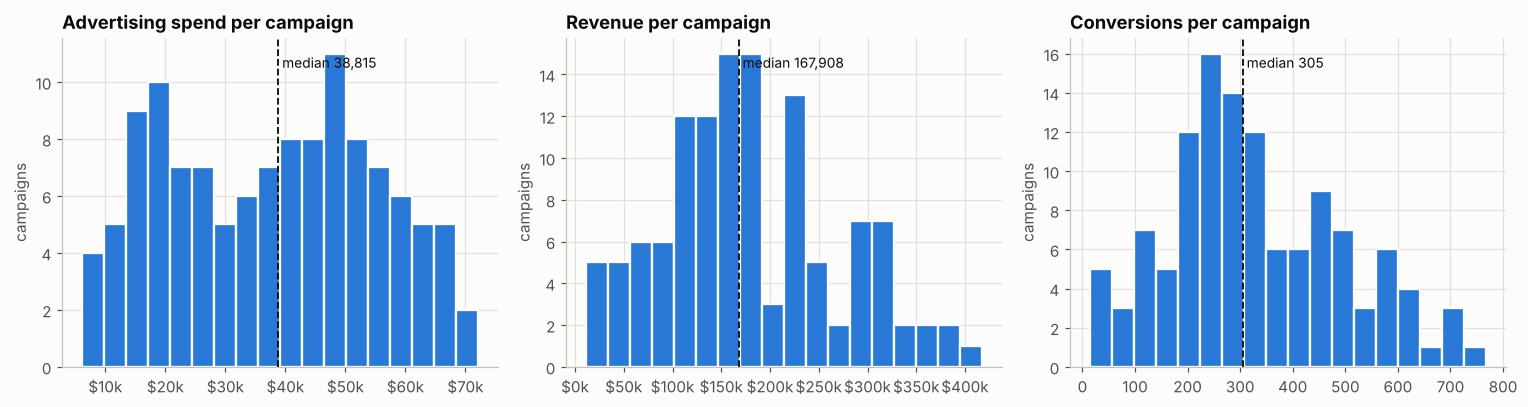

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title, fmt in zip(axes, ["spend", "revenue", "conversions"],
                               ["Advertising spend per campaign", "Revenue per campaign", "Conversions per campaign"], [usdk, usdk, None]):
    ax.hist(campaign[col], bins=18, color="#2a78d6", edgecolor=SURF, linewidth=1.5)
    ax.axvline(campaign[col].median(), color=INK, lw=1.2, ls="--")
    ax.text(campaign[col].median(), ax.get_ylim()[1] * .95, f" median {campaign[col].median():,.0f}", fontsize=9, va="top")
    ax.set_title(title); ax.set_ylabel("campaigns")
    if fmt: ax.xaxis.set_major_formatter(fmt)
plt.tight_layout(); save_fig("01_distributions")

Spend, revenue and conversions are all right-skewed: a few large campaigns carry a large part of the results (the top 10 campaigns by revenue generate about 16.5 % of total revenue).

### 4. Performance by channel

In [12]:
def group_kpis(by):
    g = campaign.groupby(by)[SUMS].sum()
    g.insert(0, "campaigns", campaign.groupby(by).size())
    return add_kpis(g)

channel = group_kpis("channel").loc[CHANNELS].sort_values("roas", ascending=False)
channel["pct_of_spend"] = 100 * channel.spend / channel.spend.sum()
channel["pct_of_revenue"] = 100 * channel.revenue / channel.revenue.sum()
channel[["campaigns", "spend", "revenue", "conversions", "pct_of_spend", "pct_of_revenue", "roas", "roi_pct", "cpa", "cost_per_purchase", "ctr_pct", "cpc", "conv_rate_pct"]]

,campaigns,spend,revenue,conversions,pct_of_spend,pct_of_revenue,roas,roi_pct,cpa,cost_per_purchase,ctr_pct,cpc,conv_rate_pct
channel,,,,,,,,,,,,,
Affiliate,24,"857,835.07","5,610,700.73",10352,18.97,26.02,6.54,554.05,82.87,198.02,2.50,0.36,0.43
Paid Search,24,"897,091.53","5,439,329.35",10019,19.83,25.23,6.06,506.33,89.54,213.39,3.49,0.52,0.58
Paid Social,24,"984,731.88","4,690,137.28",8648,21.77,21.75,4.76,376.29,113.87,270.09,1.79,0.61,0.54
Display,24,"955,297.00","3,734,117.43",6744,21.12,17.32,3.91,290.89,141.65,332.74,0.60,1.09,0.77
Video,24,"828,094.54","2,087,554.22",3933,18.31,9.68,2.52,152.09,210.55,505.55,0.89,1.68,0.80


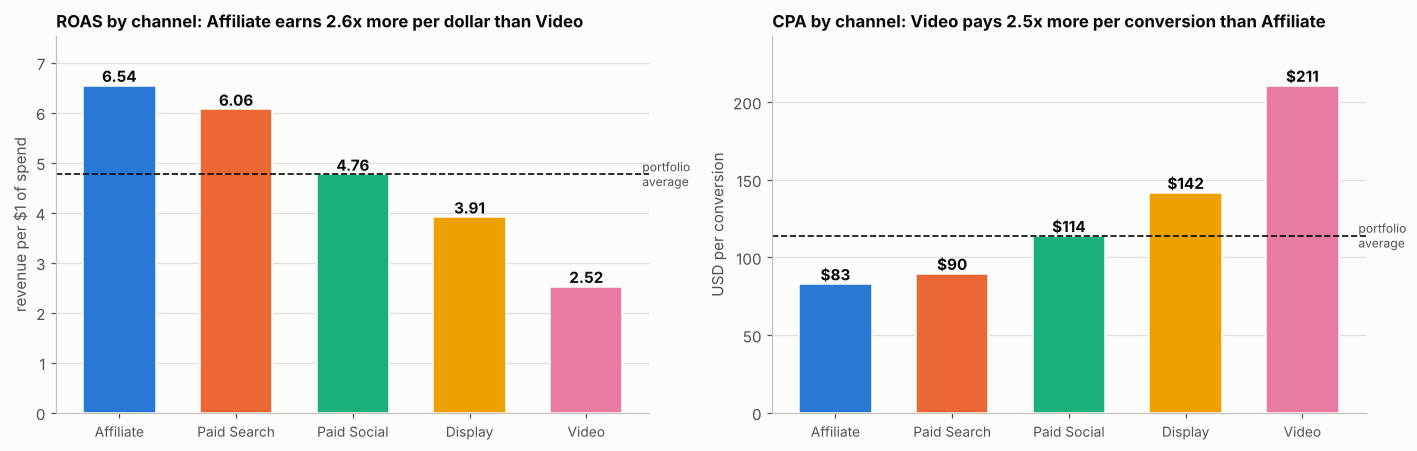

In [13]:
order = channel.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, title, fmt, base in [(axes[0], "roas", "ROAS by channel: Affiliate earns 2.6x more per dollar than Video", "{:.2f}", overall.roas.iloc[0]),
                                  (axes[1], "cpa", "CPA by channel: Video pays 2.5x more per conversion than Affiliate", "${:,.0f}", overall.cpa.iloc[0])]:
    vals = channel.loc[order, col]
    bars = ax.bar(order, vals, color=[CH_COL[c] for c in order], edgecolor=SURF, width=.62)
    ax.axhline(base, color=INK, lw=1.1, ls="--"); ax.text(4.45, base, " portfolio\n average", fontsize=8, va="center", color=MUTED)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_title(title, fontsize=11); ax.grid(axis="x", visible=False); ax.set_ylim(0, vals.max() * 1.15)
    ax.tick_params(axis="x", labelsize=9)
axes[0].set_ylabel("revenue per $1 of spend"); axes[1].set_ylabel("USD per conversion")
plt.tight_layout(); save_fig("02_roas_cpa_by_channel")

### 5. Performance by campaign objective and channel x objective

,campaigns,spend,revenue,conversions,roas,roi_pct,cpa,ctr_pct,conv_rate_pct
objective,,,,,,,,,
Acquisition,35,"1,196,910.33","6,150,234.73",11392,5.14,413.84,105.07,2.07,0.55
Awareness,44,"1,656,213.53","7,911,482.28",14438,4.78,377.68,114.71,1.71,0.55
Lead Generation,41,"1,669,926.16","7,500,122.00",13866,4.49,349.13,120.43,1.31,0.58


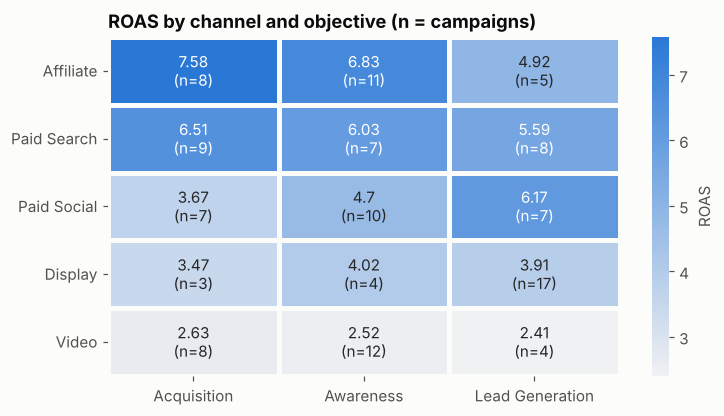

In [14]:
objective = group_kpis("objective").sort_values("roas", ascending=False)
display(objective[["campaigns", "spend", "revenue", "conversions", "roas", "roi_pct", "cpa", "ctr_pct", "conv_rate_pct"]])
mx = (campaign.groupby(["channel", "objective"]).apply(lambda d: d.revenue.sum() / d.spend.sum())
              .unstack().loc[CHANNELS])
n_mx = campaign.groupby(["channel", "objective"]).size().unstack().loc[CHANNELS]
annot = mx.round(2).astype(str) + "\n(n=" + n_mx.astype(str) + ")"
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(mx, annot=annot, fmt="", cmap=sns.light_palette("#2a78d6", as_cmap=True), cbar_kws={"label": "ROAS"}, linewidths=2, linecolor=SURF, ax=ax)
ax.set_title("ROAS by channel and objective (n = campaigns)"); ax.set_xlabel(""); ax.set_ylabel("")
save_fig("03_roas_channel_objective")

### 6. Conversions by campaign

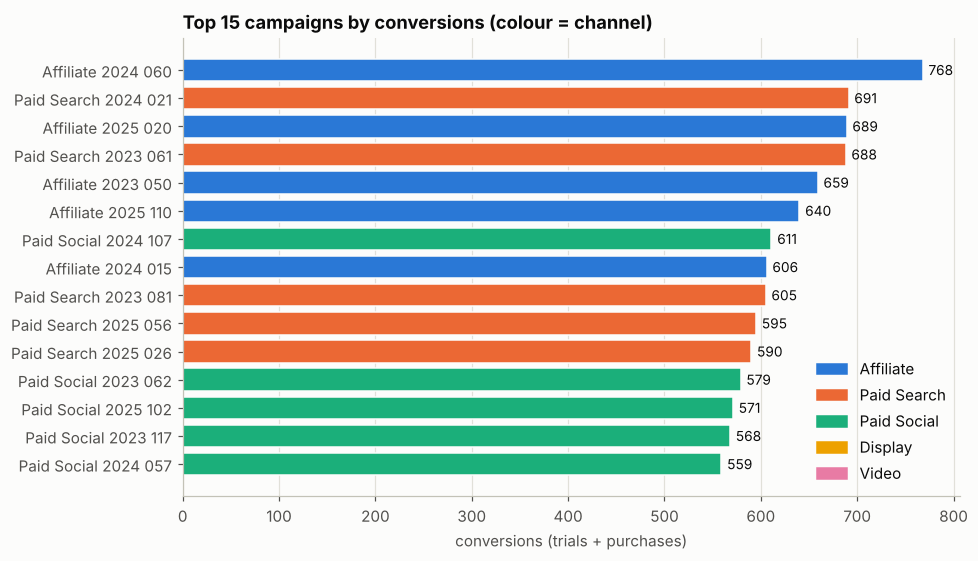

In [15]:
top = campaign.nlargest(15, "conversions").sort_values("conversions")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top.campaign_name, top.conversions, color=[CH_COL[c] for c in top.channel], edgecolor=SURF)
for y, (v, ch) in enumerate(zip(top.conversions, top.channel)): ax.text(v + 6, y, f"{v:,}", va="center", fontsize=9)
ax.set_title("Top 15 campaigns by conversions (colour = channel)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=CH_COL[c]) for c in CHANNELS], labels=CHANNELS, loc="lower right", ncol=1)
ax.set_xlabel("conversions (trials + purchases)")
plt.tight_layout(); save_fig("04_top_campaigns_conversions")

### 7. Monthly spend and revenue trends

Best month ROAS : 2025-04 6.03
ROAS by year    : {2023: 5.03, 2024: 4.44, 2025: 5.0}


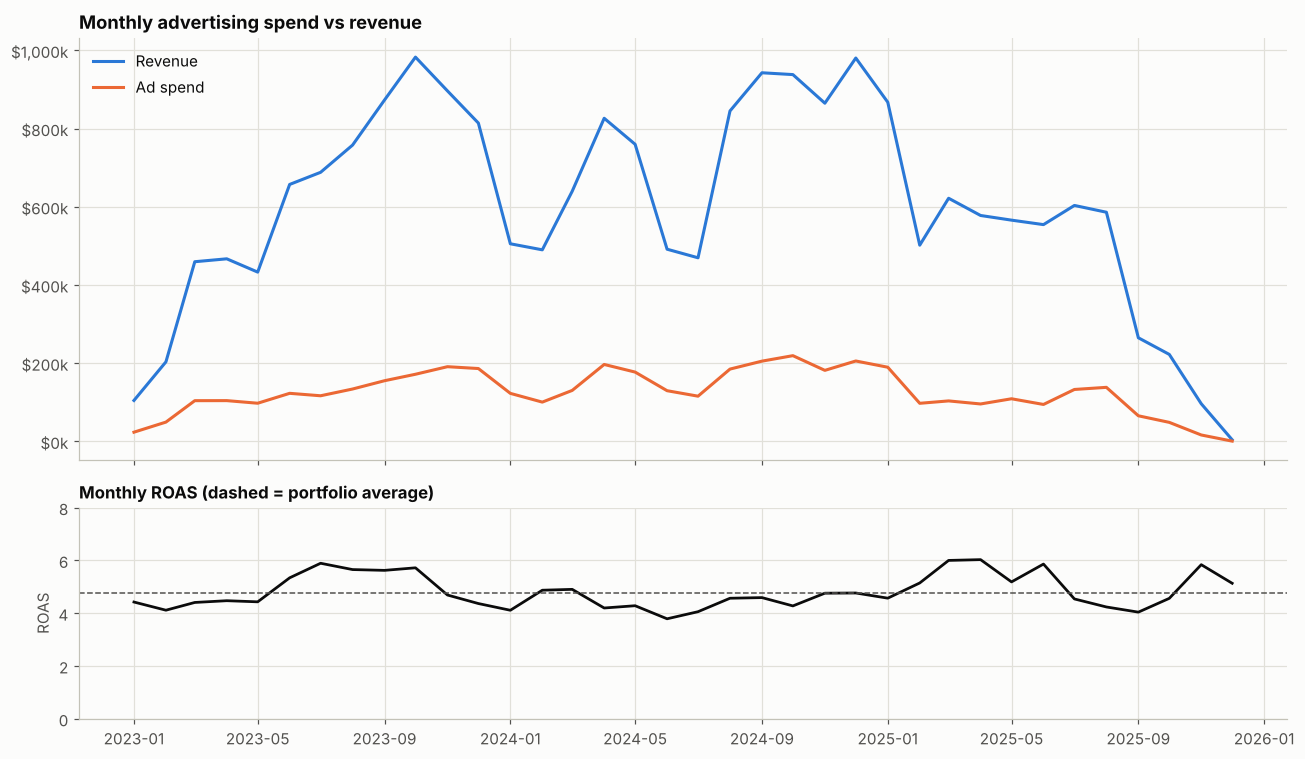

In [16]:
monthly = add_kpis(daily.groupby("month")[SUMS].sum())
monthly.index = pd.to_datetime(monthly.index)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(monthly.index, monthly.revenue, color="#2a78d6", lw=2, label="Revenue")
axes[0].plot(monthly.index, monthly.spend, color="#eb6834", lw=2, label="Ad spend")
axes[0].yaxis.set_major_formatter(usdk); axes[0].legend(loc="upper left"); axes[0].set_title("Monthly advertising spend vs revenue")
axes[1].plot(monthly.index, monthly.roas, color=INK, lw=1.8); axes[1].axhline(overall.roas.iloc[0], color=MUTED, ls="--", lw=1)
axes[1].set_title("Monthly ROAS (dashed = portfolio average)", fontsize=11); axes[1].set_ylabel("ROAS")
axes[1].set_ylim(0, 8)
plt.tight_layout(); save_fig("05_monthly_spend_revenue")
print("Best month ROAS :", monthly.roas.idxmax().strftime("%Y-%m"), round(monthly.roas.max(), 2))
print("ROAS by year    :", daily.groupby("year")[["revenue", "spend"]].sum().pipe(lambda d: (d.revenue / d.spend).round(2)).to_dict())

Revenue tracks spend closely: both build up through the second half of 2023 and of 2024 and fall back at the start of the following year. Monthly ROAS moves in a band of roughly 3.8-6.0 around the 4.77 average: there is no sustained improvement or decline over the 35 months (yearly ROAS: 5.03 in 2023, 4.44 in 2024, 5.00 in 2025), only month-to-month noise driven by the channel mix of the month.
The last months of 2025 contain little spend because the data ends on 2025-12-02.

### 8. Relationship between advertising spend and conversions

In [17]:
r, p = stats.pearsonr(campaign.spend, campaign.conversions)
rho, p_s = stats.spearmanr(campaign.spend, campaign.conversions)
print(f"Spend vs conversions - Pearson r = {r:.2f} (p = {p:.1e}), Spearman rho = {rho:.2f}")
rows = []
for ch in CHANNELS:
    d = campaign[campaign.channel == ch]
    rows.append({"channel": ch, "r(spend, conversions)": d.spend.corr(d.conversions), "r(spend, ROAS)": d.spend.corr(d.roas), "r(spend, CPA)": d.spend.corr(d.cpa)})
pd.DataFrame(rows).set_index("channel")

Spend vs conversions - Pearson r = 0.61 (p = 1.1e-13), Spearman rho = 0.61


,"r(spend, conversions)","r(spend, ROAS)","r(spend, CPA)"
channel,,,
Affiliate,0.55,-0.82,0.74
Paid Search,0.59,-0.75,0.67
Paid Social,0.81,-0.55,0.47
Display,0.98,-0.01,0.06
Video,0.99,0.09,-0.38


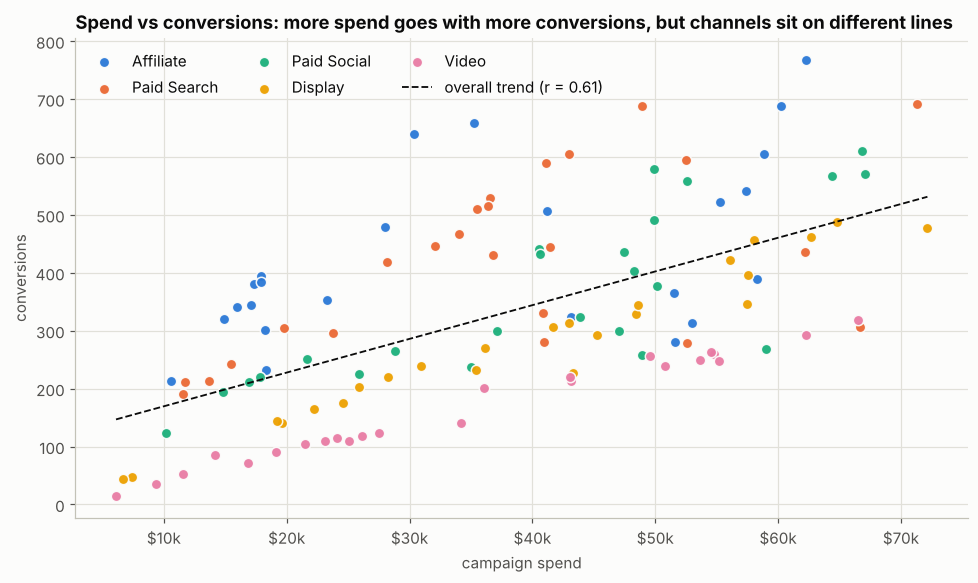

In [18]:
fig, ax = plt.subplots(figsize=(9, 5.4))
for ch in CHANNELS:
    d = campaign[campaign.channel == ch]
    ax.scatter(d.spend, d.conversions, s=46, color=CH_COL[ch], edgecolor=SURF, linewidth=1, label=ch, alpha=.95)
m, b = np.polyfit(campaign.spend, campaign.conversions, 1)
xs = np.linspace(campaign.spend.min(), campaign.spend.max(), 50)
ax.plot(xs, m * xs + b, color=INK, lw=1.2, ls="--", label=f"overall trend (r = {r:.2f})")
ax.xaxis.set_major_formatter(usdk); ax.set_xlabel("campaign spend"); ax.set_ylabel("conversions")
ax.set_title("Spend vs conversions: more spend goes with more conversions, but channels sit on different lines")
ax.title.set_fontsize(11); ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); save_fig("06_spend_vs_conversions")

**Correlation is not causation.** Larger campaigns convert more in absolute terms (r ≈ 0.61), but this is largely mechanical: bigger budgets buy more clicks.
The more useful question is efficiency. Within Affiliate (r = −0.82), Paid Search (−0.75) and Paid Social (−0.55) **larger campaigns earn a lower ROAS** – a warning sign of diminishing returns that argues against simply pouring more money into the best channel.

### Correlation between marketing KPIs

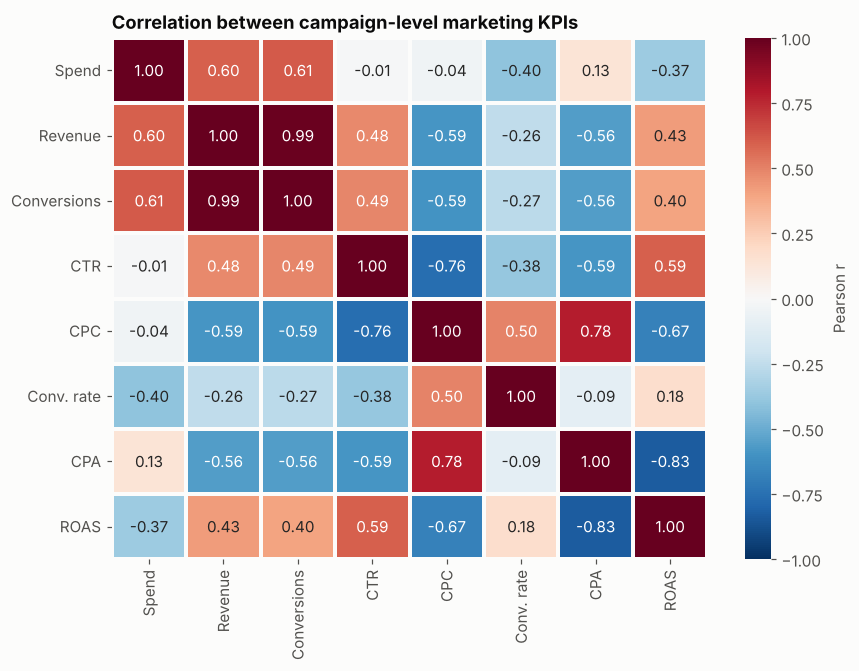

In [19]:
kp = campaign[["spend", "revenue", "conversions", "ctr_pct", "cpc", "conv_rate_pct", "cpa", "roas"]].rename(columns={
    "ctr_pct": "CTR", "cpc": "CPC", "conv_rate_pct": "Conv. rate", "cpa": "CPA", "roas": "ROAS", "spend": "Spend", "revenue": "Revenue", "conversions": "Conversions"})
fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(kp.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=1.5, linecolor=SURF, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation between campaign-level marketing KPIs"); ax.grid(False)
plt.tight_layout(); save_fig("07_kpi_correlation")

ROAS and CPA are strongly negatively correlated (r = −0.83): cheap conversions are also the ones that bring revenue, so a composite of the two (used below) is a coherent performance score.

## 4.5 Optimisation opportunities
### Performance tiers
Each campaign gets a **composite score** = average of two percentile ranks – ROAS (higher is better) and CPA (lower is better).
*High performer* ≥ 0.67, *Poor performer* ≤ 0.33, everything else *Average performer* (same rule as `04_business_analysis.sql`, Query 18).

In [20]:
n = len(campaign)
campaign["roas_pr"] = (campaign.roas.rank(method="min") - 1) / (n - 1)
campaign["cpa_pr"] = (campaign.cpa.rank(method="min", ascending=False) - 1) / (n - 1)
campaign["score"] = (campaign.roas_pr + campaign.cpa_pr) / 2
campaign["tier"] = np.select([campaign.score >= .67, campaign.score <= .33], ["High performer", "Poor performer"], "Average performer")
TIERS = ["High performer", "Average performer", "Poor performer"]
action = {"High performer": "Increase budget gradually", "Average performer": "Optimise and monitor", "Poor performer": "Reduce, restructure or pause"}

tiers = campaign.groupby("tier")[SUMS].sum().loc[TIERS]
tiers.insert(0, "campaigns", campaign.groupby("tier").size().loc[TIERS])
tiers = add_kpis(tiers); tiers["pct_of_spend"] = 100 * tiers.spend / tiers.spend.sum(); tiers["recommendation"] = [action[t] for t in TIERS]

# cross-check with SQL tiers
sql_t = pd.read_csv(os.path.join(CLEAN, "sql_campaign_tiers.csv")).set_index("campaign_id").tier
assert (campaign.set_index("campaign_id").tier.loc[sql_t.index] == sql_t).all()
print("Tier assignment identical to the SQL result.")
tiers[["campaigns", "spend", "pct_of_spend", "revenue", "conversions", "roas", "cpa", "recommendation"]]

Tier assignment identical to the SQL result.


,campaigns,spend,pct_of_spend,revenue,conversions,roas,cpa,recommendation
tier,,,,,,,,
High performer,39,"1,081,168.45",23.90,"8,627,329.22",15839,7.98,68.26,Increase budget gradually
Average performer,43,"1,911,190.08",42.25,"8,638,551.54",15838,4.52,120.67,Optimise and monitor
Poor performer,38,"1,530,691.49",33.84,"4,295,958.25",8019,2.81,190.88,"Reduce, restructure or pause"


tier,High performer,Average performer,Poor performer
channel,,,
Affiliate,16,4,4
Paid Search,17,5,2
Paid Social,6,16,2
Display,0,18,6
Video,0,0,24


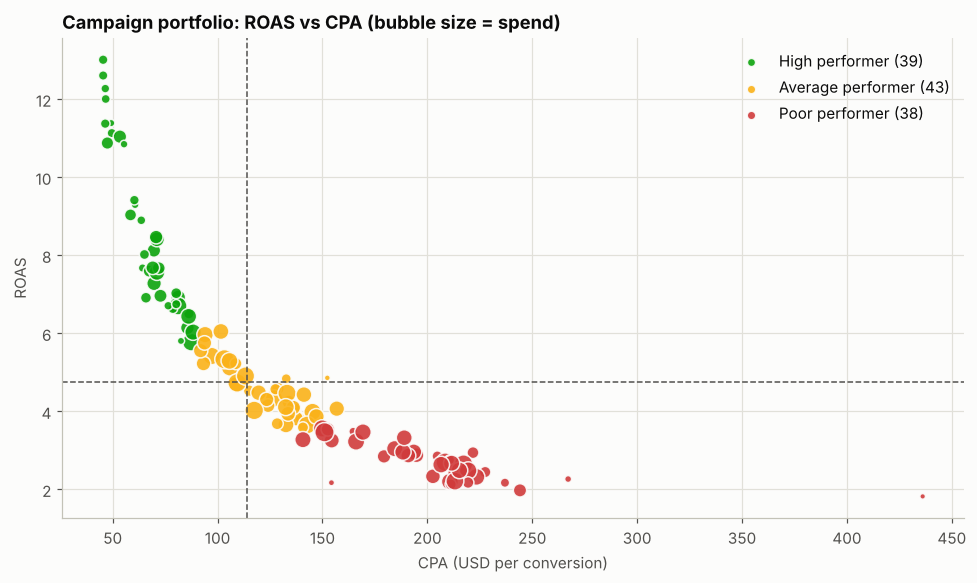

In [21]:
tier_ch = pd.crosstab(campaign.channel, campaign.tier).loc[CHANNELS, TIERS]
display(tier_ch)
fig, ax = plt.subplots(figsize=(9, 5.4))
for t in TIERS:
    d = campaign[campaign.tier == t]
    ax.scatter(d.cpa, d.roas, s=d.spend / 450, color=TIER_COL[t], edgecolor=SURF, linewidth=1, alpha=.9, label=f"{t} ({len(d)})")
ax.set_xlabel("CPA (USD per conversion)"); ax.set_ylabel("ROAS")
ax.set_title("Campaign portfolio: ROAS vs CPA (bubble size = spend)")
ax.axhline(overall.roas.iloc[0], color=MUTED, lw=1, ls="--"); ax.axvline(overall.cpa.iloc[0], color=MUTED, lw=1, ls="--")
ax.legend(loc="upper right", markerscale=.6)
plt.tight_layout(); save_fig("08_campaign_tiers")

### Campaigns spending a lot without converting enough
Rule: spend **above the average campaign** *and* conversions **below the average campaign**.

In [22]:
avg_s, avg_c = campaign.spend.mean(), campaign.conversions.mean()
leaky = campaign[(campaign.spend > avg_s) & (campaign.conversions < avg_c)].sort_values("cpa", ascending=False)
leaky = leaky.assign(cpa_vs_portfolio=leaky.cpa / overall.cpa.iloc[0])
print("by channel:", leaky.channel.value_counts().to_dict())
print(f"{len(leaky)} campaigns | spend ${leaky.spend.sum():,.0f} ({100*leaky.spend.sum()/campaign.spend.sum():.1f}% of total) | ROAS {leaky.revenue.sum()/leaky.spend.sum():.2f}")
leaky[["campaign_name", "channel", "objective", "spend", "conversions", "cpa", "cpa_vs_portfolio", "roas", "tier"]].head(12)

by channel: {'Video': 10, 'Display': 5, 'Paid Social': 4, 'Paid Search': 3, 'Affiliate': 3}
25 campaigns | spend $1,261,924 (27.9% of total) | ROAS 3.03


,campaign_name,channel,objective,spend,conversions,cpa,cpa_vs_portfolio,roas,tier
63,Video 2024 064,Video,Lead Generation,"55,178.97",247,223.40,1.96,2.32,Poor performer
66,Paid Social 2024 067,Paid Social,Acquisition,"59,042.06",269,219.49,1.93,2.48,Poor performer
40,Paid Search 2024 041,Paid Search,Acquisition,"66,691.10",307,217.23,1.91,2.65,Poor performer
103,Video 2023 104,Video,Awareness,"53,604.75",249,215.28,1.89,2.49,Poor performer
78,Video 2024 079,Video,Lead Generation,"62,230.93",292,213.12,1.87,2.21,Poor performer
108,Video 2024 109,Video,Awareness,"50,775.13",240,211.56,1.86,2.67,Poor performer
8,Video 2024 009,Video,Lead Generation,"54,786.64",260,210.72,1.85,2.20,Poor performer
23,Video 2024 024,Video,Acquisition,"66,524.17",319,208.54,1.83,2.70,Poor performer
113,Video 2024 114,Video,Awareness,"54,531.03",264,206.56,1.81,2.64,Poor performer
13,Video 2025 014,Video,Awareness,"43,162.47",213,202.64,1.78,2.34,Poor performer


### Does performance change over time? (consistency of channels)

,avg quarterly ROAS,min,max,variation coefficient,"corr(spend, ROAS) across campaigns"
channel,,,,,
Video,2.48,2.22,2.81,0.07,0.09
Display,3.83,3.19,4.38,0.09,-0.01
Paid Social,4.78,3.68,5.59,0.13,-0.55
Paid Search,6.24,4.18,8.08,0.18,-0.75
Affiliate,6.96,4.49,10.18,0.24,-0.82


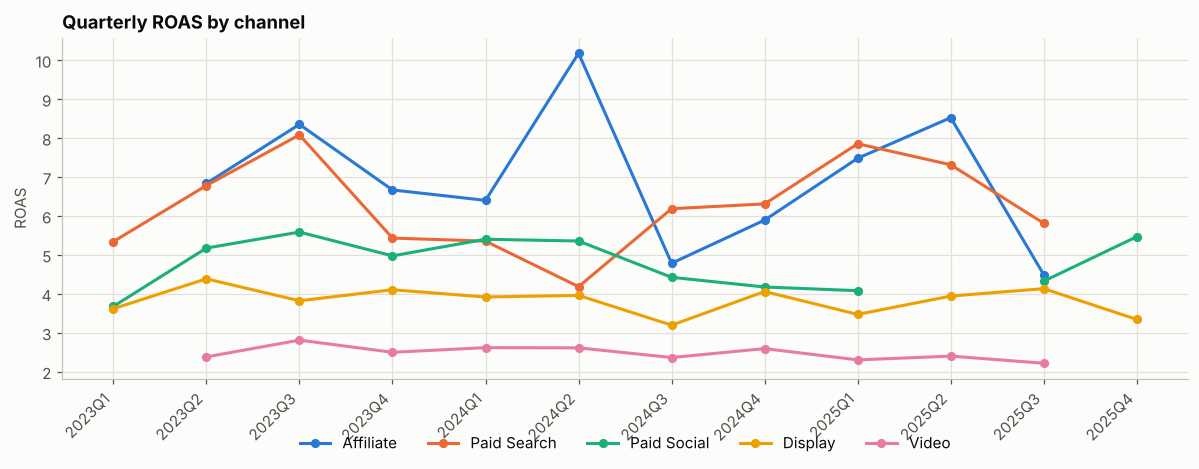

In [23]:
q = daily.groupby(["quarter", "channel"])[["spend", "revenue"]].sum()
q = q[q.spend > 10000]
qr = (q.revenue / q.spend).unstack().loc[:, CHANNELS]
fig, ax = plt.subplots(figsize=(11, 4.4))
for ch in CHANNELS: ax.plot(qr.index, qr[ch], marker="o", ms=5, lw=2, color=CH_COL[ch], label=ch)
ax.set_title("Quarterly ROAS by channel"); ax.set_ylabel("ROAS"); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(.5, -.12))
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); save_fig("09_quarterly_roas_channel")

stab = pd.DataFrame({"avg quarterly ROAS": qr.mean(), "min": qr.min(), "max": qr.max(), "variation coefficient": qr.std(ddof=0) / qr.mean(),
                     "corr(spend, ROAS) across campaigns": [campaign[campaign.channel == c].spend.corr(campaign[campaign.channel == c].roas) for c in CHANNELS]}).sort_values("variation coefficient")
stab

Video and Display are *consistently* weak (low and stable ROAS). Affiliate and Paid Search have the highest ROAS but also the most volatile quarters and the strongest "bigger campaign, lower ROAS" pattern. This is why they should be scaled **gradually and tested**, not maximised.

## Stage 6 – Budget allocation (hypothetical $100,000)
The allocation balances five criteria instead of following historical ROAS alone:
1. **Return** – ROAS and CPA of the channel.
2. **Conversion volume** – channels that actually deliver scale.
3. **Capacity / scaling risk** – the spend-vs-ROAS correlation signals diminishing returns, so shifts are capped (maximum ≈ ±12 points vs. the current mix).
4. **Objective fit** – put money into the objectives that work best *inside* each channel.
5. **Consistency over time** – volatile channels receive increases in steps.

In [24]:
BUDGET = 100_000
current = (channel.spend / channel.spend.sum()).loc[CHANNELS]
proposed_pct = pd.Series({"Affiliate": .30, "Paid Search": .27, "Paid Social": .22, "Display": .15, "Video": .06})
assert abs(proposed_pct.sum() - 1) < 1e-9
alloc = pd.DataFrame({"current_share": current, "proposed_share": proposed_pct,
                      "current_$": current * BUDGET, "proposed_$": proposed_pct * BUDGET,
                      "historical_roas": channel.roas.loc[CHANNELS], "historical_cpa": channel.cpa.loc[CHANNELS]})
alloc["change_$"] = alloc["proposed_$"] - alloc["current_$"]

# Scenario revenue (illustrative, NOT a forecast)
cur_rev = (alloc["current_$"] * alloc.historical_roas).sum()
opt_rev = (alloc["proposed_$"] * alloc.historical_roas).sum()
inc = alloc["change_$"].clip(lower=0)
cons_rev = ((alloc["proposed_$"] - inc) * alloc.historical_roas + inc * alloc.historical_roas * .5).sum()
scen = pd.DataFrame({"expected revenue on $100k": [cur_rev, cons_rev, opt_rev],
                     "implied ROAS": [cur_rev / BUDGET, cons_rev / BUDGET, opt_rev / BUDGET]},
                    index=["Current mix (baseline)", "Proposed mix - cautious (extra dollars earn only 50% of historical ROAS)", "Proposed mix - historical ROAS holds (upper bound)"])
display(alloc.round(3)); display(scen)

,current_share,proposed_share,current_$,proposed_$,historical_roas,historical_cpa,change_$
Affiliate,0.19,0.30,"18,965.85","30,000.00",6.54,82.87,"11,034.15"
Paid Search,0.20,0.27,"19,833.77","27,000.00",6.06,89.54,"7,166.23"
Paid Social,0.22,0.22,"21,771.41","22,000.00",4.76,113.87,228.59
Display,0.21,0.15,"21,120.64","15,000.00",3.91,141.65,"-6,120.64"
Video,0.18,0.06,"18,308.32","6,000.00",2.52,210.55,"-12,308.32"


,expected revenue on $100k,implied ROAS
Current mix (baseline),"476,710.16",4.77
Proposed mix - cautious (extra dollars earn only 50% of historical ROAS),"480,111.71",4.80
Proposed mix - historical ROAS holds (upper bound),"538,466.15",5.38


**How to read the scenarios:** if the extra dollars keep earning the channel's historical ROAS the mix would return about +13 % revenue; if they earn only half of it (diminishing returns) the gain is almost nil (+0.7 %). The recommendation is therefore a **hypothesis to test** (e.g. a 6-8 week split test), not a guaranteed improvement – the dataset does not measure incremental conversions.

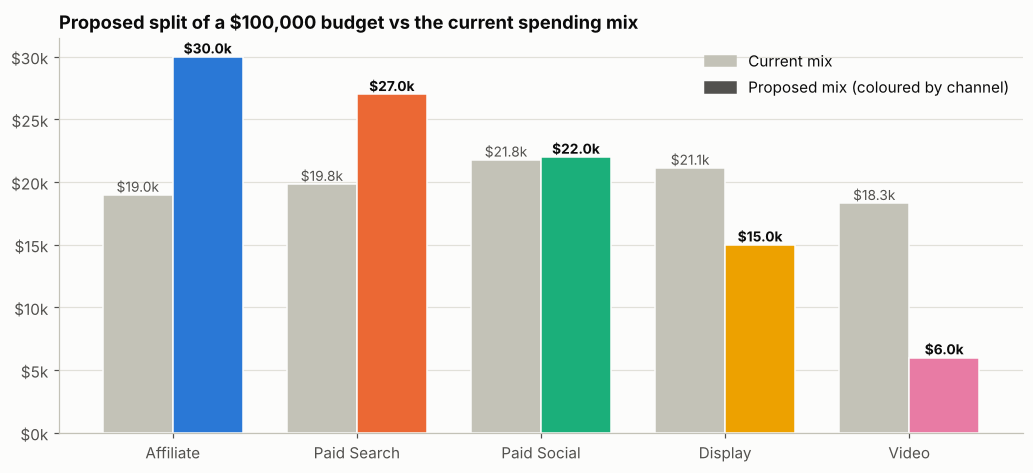

In [25]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(CHANNELS)); w = .38
ax.bar(x - w / 2, alloc["current_$"], w, color="#c3c2b7", label="Current mix", edgecolor=SURF)
bars = ax.bar(x + w / 2, alloc["proposed_$"], w, color=[CH_COL[c] for c in CHANNELS], label="Proposed mix", edgecolor=SURF)
for xi, (c, p_) in enumerate(zip(alloc["current_$"], alloc["proposed_$"])):
    ax.text(xi - w / 2, c, f"${c/1e3:.1f}k", ha="center", va="bottom", fontsize=9, color=MUTED)
    ax.text(xi + w / 2, p_, f"${p_/1e3:.1f}k", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(CHANNELS); ax.yaxis.set_major_formatter(usdk); ax.grid(axis="x", visible=False)
ax.set_title("Proposed split of a $100,000 budget vs the current spending mix"); ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#c3c2b7"), plt.Rectangle((0, 0), 1, 1, color="#52514e")], labels=["Current mix", "Proposed mix (coloured by channel)"], loc="upper right")
plt.tight_layout(); save_fig("10_budget_allocation")

## 4.6 Export results
Cleaned analytical dataset and summary tables go to `data/cleaned/`.

In [26]:
camp_out = campaign.drop(columns=["roas_pr", "cpa_pr"]).copy()
camp_out["action"] = camp_out.tier.map(action)
cols = ["campaign_id", "campaign_name", "channel", "objective", "start_date", "end_date", "budget", "days_active", "impressions", "clicks", "leads",
        "conversions", "purchases", "spend", "revenue", "ctr_pct", "cpc", "cpl", "conv_rate_pct", "cpa", "cost_per_purchase", "roas", "roi_pct",
        "budget_used_pct", "score", "tier", "action"]
camp_out = camp_out[cols].sort_values("campaign_id")
daily_out = daily[["spend_date", "campaign_id", "campaign_name", "channel", "objective", "month", "impressions", "clicks", "leads", "conversions", "purchases", "spend", "revenue"]] \
    .sort_values(["spend_date", "campaign_id"]).assign(spend_date=lambda d: d.spend_date.dt.strftime("%Y-%m-%d"))
camp_out.assign(start_date=camp_out.start_date.dt.strftime("%Y-%m-%d"), end_date=camp_out.end_date.dt.strftime("%Y-%m-%d")).round(4).to_csv(os.path.join(CLEAN, "analytical_dataset_campaigns.csv"), index=False)
daily_out.round(2).to_csv(os.path.join(CLEAN, "cleaned_daily_performance.csv"), index=False)
channel.reset_index().round(4).to_csv(os.path.join(CLEAN, "summary_channel.csv"), index=False)
objective.reset_index().round(4).to_csv(os.path.join(CLEAN, "summary_objective.csv"), index=False)
monthly.reset_index().assign(month=lambda d: d.month.dt.strftime("%Y-%m")).round(4).to_csv(os.path.join(CLEAN, "summary_monthly.csv"), index=False)
alloc.reset_index().rename(columns={"index": "channel"}).round(4).to_csv(os.path.join(CLEAN, "budget_allocation_100k.csv"), index=False)
print(sorted(f for f in os.listdir(CLEAN) if f.endswith(".csv")))

['analytical_dataset_campaigns.csv', 'budget_allocation_100k.csv', 'cleaned_daily_performance.csv', 'sql_campaign_kpis.csv', 'sql_campaign_tiers.csv', 'sql_channel_kpis.csv', 'sql_monthly_kpis.csv', 'sql_objective_kpis.csv', 'summary_channel.csv', 'summary_monthly.csv', 'summary_objective.csv']


## Key findings
1. **Data quality is high** – no missing values, duplicates, orphan IDs or invalid dates; all funnel logic holds. The only issues are technical (text-typed numbers in the workbook, 58 % of conversions are zero-revenue trials).
2. **Portfolio**: $4.52M spend generated $21.56M attributed revenue → **ROAS 4.77**, ROI 377 %, 39,696 conversions (CPA $113.94; cost per *purchase* $270.99).
3. **Channels** – Affiliate (ROAS 6.54, CPA $83) and Paid Search (6.06, $90) are the efficient engines; Paid Social is mid-pack (4.76); Display (3.91) and Video (2.52, CPA $211) lag. Video takes 18 % of spend for 10 % of revenue.
4. **Objectives** – Acquisition (ROAS 5.14) > Awareness (4.78) > Lead Generation (4.49), but the best objective depends on the channel (e.g. Paid Social: Lead Gen 6.17 vs Acquisition 3.67).
5. **Waste** – 38 *poor performer* campaigns absorb 34 % of the budget at ROAS 2.8; 25 high-spend / low-conversion campaigns hold 28 % of the budget at ROAS 3.0; Video is the largest group (10 of 25).
6. **Stability** – no sustained trend over time; seasonality peaks in Q3-Q4. Affiliate/Paid Search are the most volatile.
7. **Scaling risk** – bigger Affiliate/Paid Search/Paid Social campaigns have lower ROAS, so budget moves must be tested in steps.
8. **Recommendation** – shift from Video/Display toward Affiliate/Paid Search: $30k / $27k / $22k / $15k / $6k (Affiliate / Paid Search / Paid Social / Display / Video), presented as an experiment to validate, not a guaranteed uplift.